EDA

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [3]:

df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

In [4]:
# Check size

print("Average Levels Shape:", df_avg.shape)
print("Station Locations Shape:", df_locs.shape)

Average Levels Shape: (392, 4382)
Station Locations Shape: (392, 5)


In [5]:
# Inspect the first few rows of the locations and average levels
display(df_locs.head())
display(df_avg.head(2))

,County,Station_Name,Observation_ID,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,57.424758,-2.802015
1,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,57.075424,-2.335825
2,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,57.055146,-3.083181
3,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,57.050129,-2.603567
4,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,56.988040,-3.486198


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669


In [7]:
# Missing entries

# Check how many missing (NaN) days each station has across the 4,382 columns
missing_per_station = df_avg.isna().sum(axis=1)

print(missing_per_station.head())

0    1085
1    1091
2    1087
3    1089
4    1093
dtype: int64


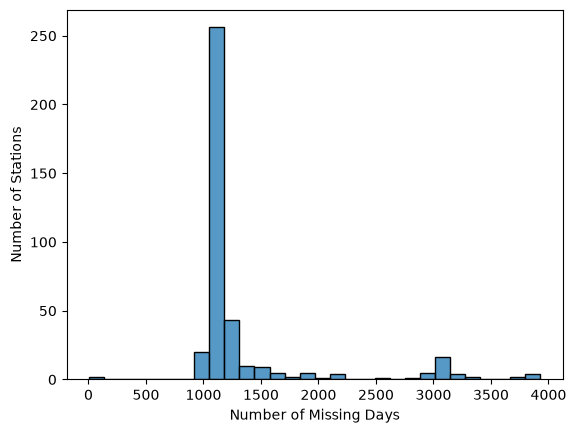

In [10]:
# Plot a histogram of missing data across all stations
sns.histplot(missing_per_station, bins=30)
plt.xlabel("Number of Missing Days")
plt.ylabel("Number of Stations")
plt.show()

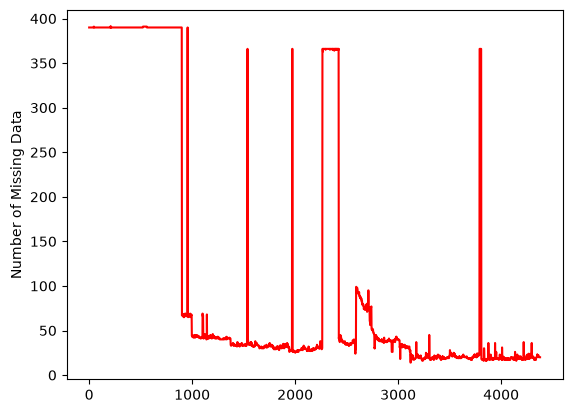

In [13]:
# Count how many stations are missing data on each individual day
# drop first three text columns, only looking at dates
missing_by_date = df_avg.drop(columns=['County', 'Station_Name', 'Observation_ID']).isna().sum()


plt.plot(missing_by_date.values, color='red')
plt.ylabel("Number of Missing Data")
plt.show()

Remove first dates with no data

In [17]:
# Drop dates that do not have at least 300 non-missing values
df_clean = df_avg.dropna(thresh=300, axis=1)

# Check the new shape
print(df_clean.shape)

(392, 3274)


Splitting the data

In [18]:
metadata_cols = ['County', 'Station_Name', 'Observation_ID']
date_cols = [col for col in df_clean.columns if col not in metadata_cols]

# training data first date - end of August 2026
train_dates = [col for col in date_cols if pd.to_datetime(col, format='%d/%m/%Y') <= pd.to_datetime('2026-08-31')]

# testing data: September, October, November 2026
test_dates = [col for col in date_cols if pd.to_datetime(col, format='%d/%m/%Y') >= pd.to_datetime('2026-09-01')]

X_train = df_clean[metadata_cols + train_dates]
X_test = df_clean[metadata_cols + test_dates]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (392, 3236)
Testing Data Shape: (392, 41)


In [19]:
# Check if there is still any missing values

print("Total missing values in Training Data:", X_train.isna().sum().sum())
print("Total missing values in Testing Data:", X_test.isna().sum().sum())

Total missing values in Training Data: 103967
Total missing values in Testing Data: 794


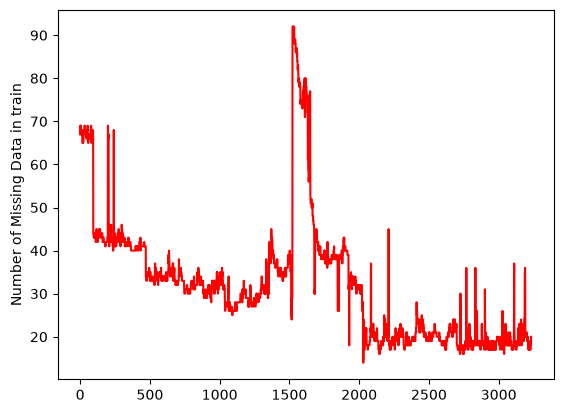

In [21]:
# Same plot as before of train to explore

missing_by_date_train = X_train.drop(columns=['County', 'Station_Name', 'Observation_ID']).isna().sum()

plt.plot(missing_by_date_train.values, color='red')
plt.ylabel("Number of Missing Data in train")
plt.show()

Pipeline

In [25]:
X_num = X_train.drop(columns=['County', 'Station_Name', 'Observation_ID'])
y_num = X_test.drop(columns=['County', 'Station_Name', 'Observation_ID'])

imputer = SimpleImputer(strategy="median")
X_clean = imputer.fit_transform(X_num)
y_clean = imputer.fit_transform(y_num)

baseline_pipe = Pipeline([
    ("model", LinearRegression())
])
baseline_pipe.fit(X_clean, y_clean)

# R-squared
score = baseline_pipe.score(X_clean, y_clean)
print(f"Baseline Model R-squared Score: {score}")

Baseline Model R-squared Score: 0.996750443226927


Group Data Processing:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view

# 1. Load datasets
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# 2. finalized preprocessing function
def prepare_data(df):
    date_cols = df.columns[3:]
    data = df[date_cols].apply(pd.to_numeric, errors="coerce")
    
    # Scrub impossible sensor errors (|level| > 30m)
    data = data.mask(data.abs() > 30)
    
    # Convert to datetime, sort chronologically, and fill missing calendar days with NaN
    data.columns = pd.to_datetime(date_cols, dayfirst=True)
    data = data.sort_index(axis=1)
    all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")
    data = data.reindex(columns=all_dates)
    
    # Drop the first 908 dates (Oct 2014 - March 2017) where ~390 stations were inactive
    data = data.iloc[:, 908:]
    
    # Transpose so Dates are rows and Station indices (0-391) are columns
    return data.T

avg = prepare_data(df_avg)
minimum = prepare_data(df_min)
maximum = prepare_data(df_max)

# 3. valid 7-day (+1 target day) window extractor
def get_valid_windows(df):
    numeric_vals = df.to_numpy(float)
    dates = df.index
    
    # 8-day window: Days 1-7 (features) + Day 8 (Next Day target)
    period = sliding_window_view(numeric_vals, 8, axis=0)
    nan_present = ~np.isnan(period).any(axis=2)
    
    ID_name, date_start_name = np.nonzero(nan_present.T)
    valid_periods = period[date_start_name, ID_name, :]
    
    return pd.DataFrame({
        "ID": df.columns[ID_name],
        "Week starting": dates[date_start_name],
        "Day 1": valid_periods[:, 0],
        "Day 2": valid_periods[:, 1],
        "Day 3": valid_periods[:, 2],
        "Day 4": valid_periods[:, 3],
        "Day 5": valid_periods[:, 4],
        "Day 6": valid_periods[:, 5],
        "Day 7": valid_periods[:, 6],
        "Next Day": valid_periods[:, 7]
    })

df_windows = get_valid_windows(avg)
print("Total valid 7-day + next-day windows:", df_windows.shape[0])

Total valid 7-day + next-day windows: 1165020


In [3]:

# 7-day window down the rows (dates) for all 392 stations at once
windows_7day = sliding_window_view(avg.to_numpy(float), 7, axis=0)

# Check each 7-day window: True if NO days in that 7-day stretch are NaN
is_valid_7day = ~np.isnan(windows_7day).any(axis=2)

# Sum up the True values down the timeline for each of the 392 stations
valid_counts = is_valid_7day.sum(axis=0)

# Attach the station names so the output is easy to read
valid_per_station = pd.Series(valid_counts, index=df_avg["Station_Name"])
print("Valid 7-day periods per station (first 5 stations):")
print(valid_per_station.head())
print("\nSummary across all 392 stations:")
print(valid_per_station.describe())


# Chronological 70/30 Split
# Sort by station ID first, then chronologically by date
df_windows = df_windows.sort_values(["ID", "Week starting"]).reset_index(drop=True)

# Calculate each row's chronological position (from 0.0 to 1.0) within its own station
row_number = df_windows.groupby("ID").cumcount()
total_rows_per_station = df_windows.groupby("ID")["ID"].transform("count")
df_windows["time_pct"] = row_number / total_rows_per_station

# First 70% of each station's timeline goes to train; last 30% goes to test
train_df = df_windows[df_windows["time_pct"] < 0.70].copy()
test_df  = df_windows[df_windows["time_pct"] >= 0.70].copy()


# Define Flood Events (99th Percentile per Station)
# 8. Calculate the 99th percentile water level for EACH station using ONLY train_df
QUANTILE = 0.99  # test 0.95 later
station_thresholds = train_df.groupby("ID")["Next Day"].quantile(QUANTILE)

# Label Flood = 1 if 'Next Day' exceeds that station's threshold, else 0
train_df["Flood"] = (train_df["Next Day"] > train_df["ID"].map(station_thresholds)).astype(int)
test_df["Flood"]  = (test_df["Next Day"] > test_df["ID"].map(station_thresholds)).astype(int)

# Check the sizes and flood proportions in both splits
print(f"\nTrain rows: {len(train_df)} | Test rows: {len(test_df)}")
print(f"Train flood proportion: {train_df['Flood'].mean() * 100:.2f}%")
print(f"Test flood proportion:  {test_df['Flood'].mean() * 100:.2f}%")

Valid 7-day periods per station (first 5 stations):
Station_Name
Bogie, Redcraig               3258
Dee (Grampian), Mar Lodge     3240
Dee (Grampian), Park          3250
Dee (Grampian), Polhollick    3242
Dee (Grampian), Woodend       3238
dtype: int64

Summary across all 392 stations:
count     392.000000
mean     2980.094388
std       615.702530
min       440.000000
25%      3079.750000
50%      3228.000000
75%      3251.000000
max      3459.000000
dtype: float64

Train rows: 815701 | Test rows: 349319
Train flood proportion: 1.02%
Test flood proportion:  1.06%


⁠SVC/SVM/MMC: